In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# uploading file path
from google.colab import files
uploaded = files.upload()
file_path = "ABP_2.csv"

data = pd.read_csv(file_path, skiprows=3, header=None)

# x/c and y/c coords
x_c = data.iloc[0, 9:30].astype(float).to_numpy()
y_c = data.iloc[1, 9:30].astype(float).to_numpy()
# aoa and dynamic pressure
alpha = data.iloc[2:, 1].astype(float).to_numpy()
q_inf = data.iloc[2:, 2].astype(float).to_numpy()
# surface pressure
pressure = data.iloc[2:, 9:30].astype(float).to_numpy()

Cp = pressure/q_inf[:, None]

# upper coords
x_upper = x_c[:11][::-1]
y_upper = y_c[:11][::-1]

# lower coords
x_lower = x_c[10:]
y_lower = y_c[10:]

Saving ABP_2.csv to ABP_2.csv


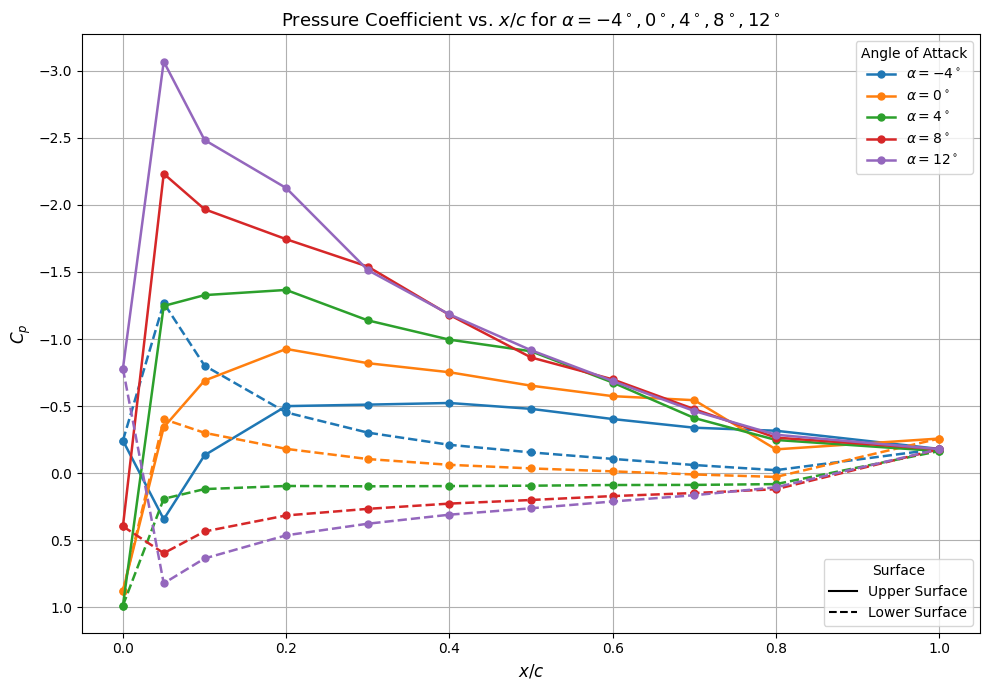

In [ ]:
# part 1 graph
from matplotlib.lines import Line2D

angles_1 = [-4, 0, 4, 8, 12]
plt.figure(figsize=(10, 7))
for angle in angles_1:
    i = np.where(alpha == angle)[0][0]

    Cp_up = Cp[i, :11][::-1]
    Cp_low = Cp[i, 10:]

    # upper surface
    line, = plt.plot(x_upper,Cp_up,marker='o',linewidth=1.8,markersize=5,label=fr'$\alpha = {angle}^\circ$')

    # lower surface
    plt.plot(x_lower,Cp_low,marker='o',linestyle='--',linewidth=1.8,markersize=5,color=line.get_color())

# -Cp upwards
plt.gca().invert_yaxis()
plt.xlabel(r'$x/c$', fontsize=12)
plt.ylabel(r'$C_p$', fontsize=12)
plt.title(r'Pressure Coefficient vs. $x/c$ for $\alpha = -4^\circ, 0^\circ, 4^\circ, 8^\circ, 12^\circ$',fontsize=13)
plt.grid(True)
surface_legend = [Line2D([0], [0], color='black', linestyle='-', label='Upper Surface'),Line2D([0], [0], color='black', linestyle='--', label='Lower Surface')]
legend1 = plt.legend(title='Angle of Attack', loc='upper right')
plt.gca().add_artist(legend1)
plt.legend(handles=surface_legend, title='Surface', loc='lower right')
plt.tight_layout()
plt.show()

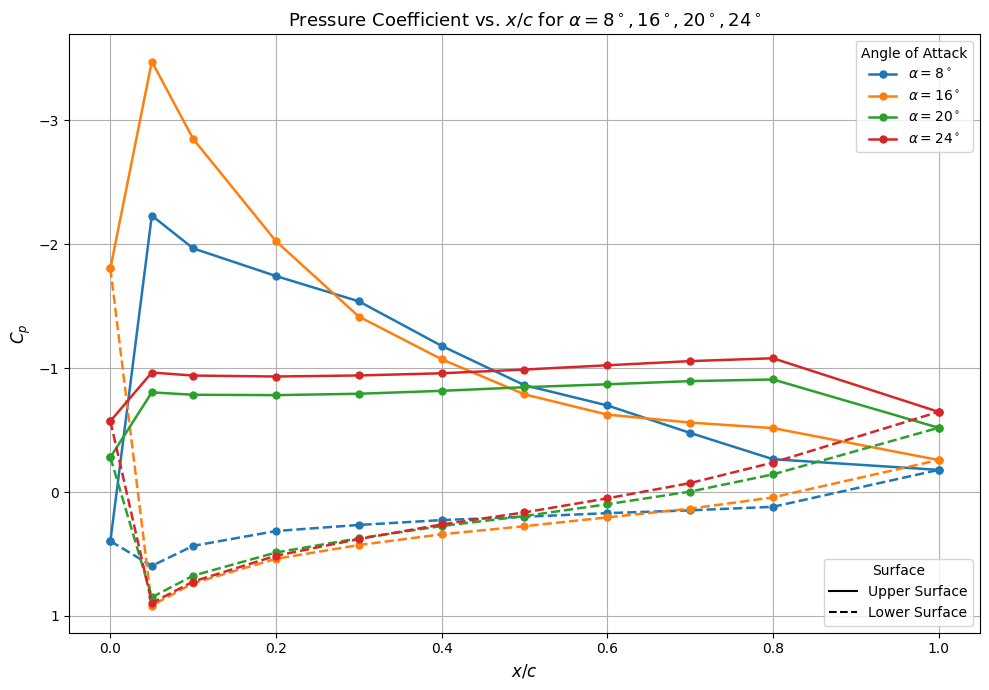

In [ ]:
# part 2 graph
from matplotlib.lines import Line2D

angles_2 = [8, 16, 20, 24]
plt.figure(figsize=(10, 7))
for angle in angles_2:
    i = np.where(alpha == angle)[0][0]

    Cp_up = Cp[i, :11][::-1]
    Cp_low = Cp[i, 10:]

    # upper surface
    line, = plt.plot(x_upper,Cp_up,marker='o',linewidth=1.8,markersize=5,label=fr'$\alpha = {angle}^\circ$')

    # lower surface
    plt.plot(x_lower,Cp_low,marker='o',linestyle='--',linewidth=1.8,markersize=5,color=line.get_color())

# -Cp upwards
plt.gca().invert_yaxis()
plt.xlabel(r'$x/c$', fontsize=12)
plt.ylabel(r'$C_p$', fontsize=12)
plt.title(r'Pressure Coefficient vs. $x/c$ for $\alpha = 8^\circ, 16^\circ, 20^\circ, 24^\circ$',fontsize=13)
plt.grid(True)
surface_legend = [Line2D([0], [0], color='black', linestyle='-', label='Upper Surface'),Line2D([0], [0], color='black', linestyle='--', label='Lower Surface')]
legend1 = plt.legend(title='Angle of Attack', loc='upper right')
plt.gca().add_artist(legend1)
plt.legend(handles=surface_legend, title='Surface', loc='lower right')
plt.tight_layout()
plt.show()

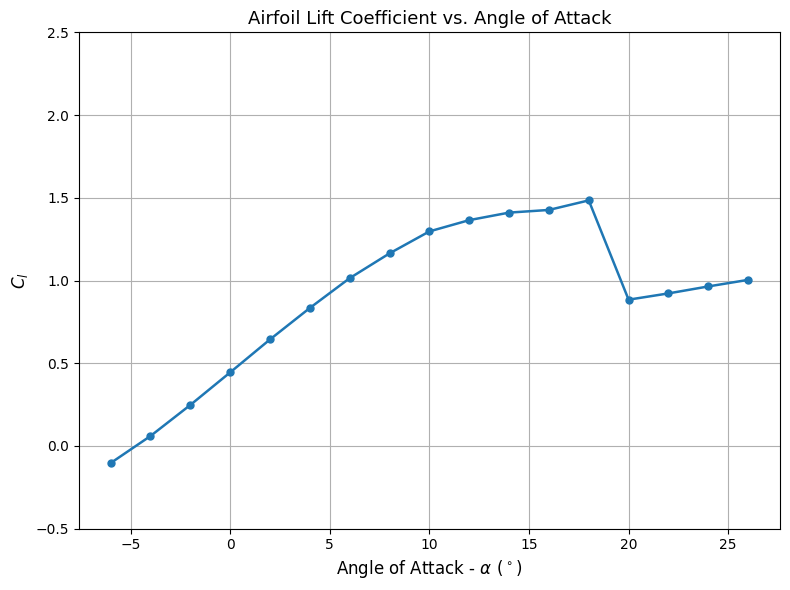

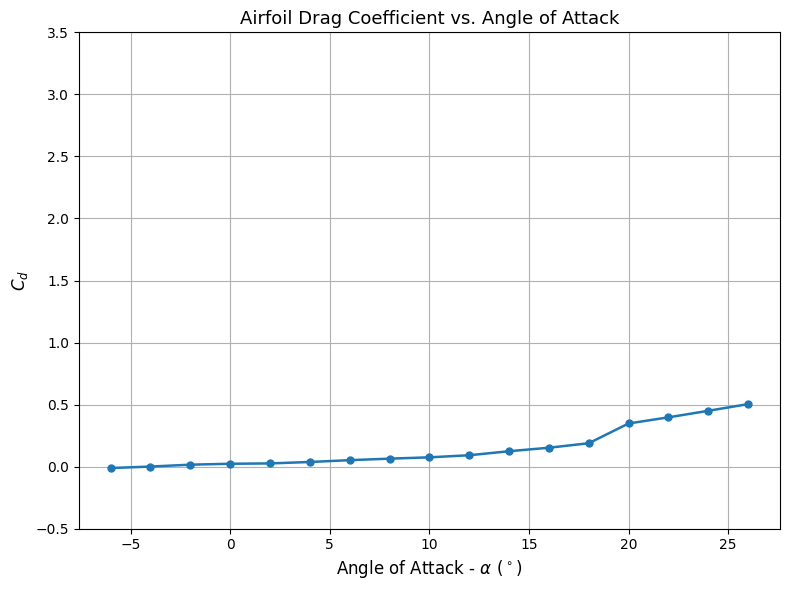

In [ ]:
# part 4
# coefficients
Cn = [] # normal
Ca = [] # axial
CL = [] # lift
CD = [] # drag

dx_c = np.diff(x_c)
dy_c = np.diff(y_c)

for i in range(len(alpha)):
    Cp_i = Cp[i, :]
    Cp_avg = 0.5 * (Cp_i[:-1] + Cp_i[1:])

    Cn_i = np.sum(Cp_avg * dx_c)
    Ca_i = -np.sum(Cp_avg * dy_c)

    alpha_rad = np.deg2rad(alpha[i])

    CL_i = Cn_i * np.cos(alpha_rad) - Ca_i * np.sin(alpha_rad)
    CD_i = Cn_i * np.sin(alpha_rad) + Ca_i * np.cos(alpha_rad)

    Cn.append(Cn_i)
    Ca.append(Ca_i)
    CL.append(CL_i)
    CD.append(CD_i)

Cn = np.array(Cn)
Ca = np.array(Ca)
CL = np.array(CL)
CD = np.array(CD)

# cl vs. aoa plot
plt.figure(figsize=(8, 6))
plt.plot(alpha,CL,marker='o',linewidth=1.8,markersize=5)
plt.xlabel(r'Angle of Attack - $\alpha$ ($^\circ$)', fontsize=12)
plt.ylabel(r'$C_l$', fontsize=12)
plt.title(r'Airfoil Lift Coefficient vs. Angle of Attack', fontsize=13)
plt.ylim(-0.5,2.5)
plt.grid(True)
plt.tight_layout()
plt.show()

# cd vs. aoa plot
plt.figure(figsize=(8, 6))
plt.plot(alpha,CD,marker='o',linewidth=1.8,markersize=5)
plt.xlabel(r'Angle of Attack - $\alpha$ ($^\circ$)', fontsize=12)
plt.ylabel(r'$C_d$', fontsize=12)
plt.title(r'Airfoil Drag Coefficient vs. Angle of Attack', fontsize=13)
plt.ylim(-0.5,3.5)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
print(CL)
print(CD)